# Nature-Inspired Feature Selection for IDS — GA vs PSO vs ACO
Companion code for *Assignment 2 — Nature-Inspired Feature Selection*
(GA / PSO / ACO wrapper feature selection + Random Forest, on **NSL-KDD** and **CIC-IDS-2017**).

**How this notebook keeps runtime short**
- A `FAST_MODE` switch (next config cell) uses a small population/iteration count and a
  row-subsample during the search phase — the final selected subset is still evaluated on
  the **full** held-out test set with a full-size Random Forest, so the reported detection
  rate / FPR / F1 are trustworthy numbers, just found faster.
- Set `FAST_MODE = False` only when you want the exact Table II–IV settings from the
  writeup (population=50, iterations=100) — that pass can take a long time on a CPU
  runtime, so budget accordingly or run it as a background/overnight session.
- The statistical-validation cell (Wilcoxon/Friedman, `N_STAT_RUNS` repetitions) is by far
  the slowest part. Run the main-results cell first; only run the statistics cell once
  that works and you actually need Section IV-F's significance numbers.

**Expected folder layout under `PROJECT_PATH`**
```
Nature-Inspired Computing/
├── data/
│   ├── NSL-KDD/
│   │   ├── KDDTrain+.txt
│   │   └── KDDTest+.txt
│   └── CIC_IDS_2017/
│       └── *.csv            (the original per-day CICIDS2017 CSV files)
└── results/                  (created automatically)
```
If your files live somewhere else, just edit `NSLKDD_DIR` / `CICIDS_DIR` in the CONFIG cell.


In [ ]:
# ============================================================
# ENVIRONMENT SETUP  (works on Google Colab and locally)
# ============================================================
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_PATH = "/content/drive/MyDrive/Nature-Inspired Computing"
except ImportError:
    # Running locally: project root is the parent of the notebooks/ folder
    PROJECT_PATH = os.path.abspath("..")

print("Project path:", PROJECT_PATH, "| exists:", os.path.exists(PROJECT_PATH))


In [47]:
# ============================================================
# IMPORTS
# ============================================================
import numpy as np
import pandas as pd
import glob, os, time, random, warnings
warnings.filterwarnings("ignore")

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from scipy.stats import wilcoxon, friedmanchisquare

np.random.seed(42)
random.seed(42)


In [48]:
# ============================================================
# CONFIGURATION  ---  EDIT THIS CELL TO MATCH YOUR FOLDER LAYOUT
# ============================================================
NSLKDD_DIR  = os.path.join(PROJECT_PATH, "data", "NSL-KDD")
CICIDS_DIR  = os.path.join(PROJECT_PATH, "data", "CIC_IDS_2017", "MachineLearningCVE")
RESULTS_DIR = os.path.join(PROJECT_PATH, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---- SPEED CONTROLS -----------------------------------------------------
# FAST_MODE=True finishes all 3 algorithms x 2 datasets in a few minutes on
# a standard Colab CPU runtime. Set False for the exact Table II-IV numbers
# from the writeup (much slower).
FAST_MODE = True

if FAST_MODE:
    POP_SIZE        = 12     # population / swarm / colony size
    N_GEN           = 8      # generations / iterations
    CV_FOLDS        = 3      # cross-validation folds used INSIDE fitness
    RF_TREES_SEARCH = 40     # small forest used only during the search
    SUBSAMPLE_ROWS  = 6000   # rows used to evaluate fitness (search phase)
    N_STAT_RUNS     = 5      # independent runs per algorithm for stats
else:
    POP_SIZE        = 50
    N_GEN           = 100
    CV_FOLDS        = 5
    RF_TREES_SEARCH = 100
    SUBSAMPLE_ROWS  = None   # use the full training set
    N_STAT_RUNS     = 30

RF_TREES_FINAL = 100   # final Random Forest (Table V) always uses 100 trees
W1, W2 = 0.9, 0.1       # fitness weights (Eq. 2 / Eq. 7 in Assignment 2)


In [49]:
# ============================================================
# LOAD NSL-KDD
# ============================================================
def load_nslkdd(nslkdd_dir):
    """
    Expects the standard NSL-KDD release: KDDTrain+.txt , KDDTest+.txt
    (no header row, 43 comma-separated columns: 41 features + class + difficulty).
    Download: https://www.unb.ca/cic/datasets/nsl.html
    """
    columns = [
        "duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
        "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
        "root_shell","su_attempted","num_root","num_file_creations","num_shells",
        "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
        "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
        "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
        "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
        "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
        "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate",
        "class","difficulty"
    ]
    def _resolve(name):
        # supports both data/NSL-KDD/KDDTrain+.txt and the nested
        # data/NSL-KDD/KDDTrain+.txt/KDDTrain+.txt layout produced by Drive unzips
        p = os.path.join(nslkdd_dir, name)
        return os.path.join(p, name) if os.path.isdir(p) else p

    train_path = _resolve("KDDTrain+.txt")
    test_path  = _resolve("KDDTest+.txt")
    assert os.path.exists(train_path), f"Missing file: {train_path}"
    assert os.path.exists(test_path),  f"Missing file: {test_path}"

    train_df = pd.read_csv(train_path, names=columns)
    test_df  = pd.read_csv(test_path,  names=columns)
    train_df.drop(columns=["difficulty"], inplace=True)
    test_df.drop(columns=["difficulty"], inplace=True)

    # binary label: normal -> 0, any attack -> 1  (matches DR / FPR in Section IV-D)
    train_df["label"] = (train_df["class"].str.lower() != "normal").astype(int)
    test_df["label"]  = (test_df["class"].str.lower()  != "normal").astype(int)
    train_df.drop(columns=["class"], inplace=True)
    test_df.drop(columns=["class"], inplace=True)
    return train_df, test_df


In [50]:
# ============================================================
# LOAD CIC-IDS-2017
# ============================================================
def load_cicids2017(cicids_dir, row_cap=150000, random_state=42):
    """
    Expects the original per-day CICIDS2017 CSV files placed directly inside
    cicids_dir (e.g. the 'MachineLearningCVE' release). All CSVs are
    concatenated; if the result has more than row_cap rows it is
    stratified-downsampled so the wrapper search stays tractable in Colab.
    """
    csv_files = glob.glob(os.path.join(cicids_dir, "*.csv"))
    assert len(csv_files) > 0, f"No CSV files found in {cicids_dir}"

    frames = []
    for f in csv_files:
        df = pd.read_csv(f, low_memory=False)
        df.columns = [c.strip() for c in df.columns]
        frames.append(df)
    full = pd.concat(frames, ignore_index=True)

    full.rename(columns={"Label": "class"}, inplace=True)
    full["class"] = full["class"].astype(str).str.strip()
    full["label"] = (full["class"].str.upper() != "BENIGN").astype(int)
    full.drop(columns=["class"], inplace=True)

    # drop rows with inf/NaN produced by CICFlowMeter (e.g. Flow Bytes/s)
    full.replace([np.inf, -np.inf], np.nan, inplace=True)

    if row_cap is not None and len(full) > row_cap:
        full, _ = train_test_split(
            full, train_size=row_cap, stratify=full["label"], random_state=random_state
        )

    train_df, test_df = train_test_split(
        full, test_size=0.20, stratify=full["label"], random_state=random_state
    )
    return train_df.reset_index(drop=True), test_df.reset_index(drop=True)


In [51]:
# ============================================================
# PREPROCESSING (Section III-B: imputation, one-hot, min-max normalisation)
# ============================================================
def preprocess(train_df, test_df, label_col="label"):
    train_df = train_df.copy()
    test_df  = test_df.copy()

    thresh = int(0.5 * train_df.shape[1])
    train_df.dropna(thresh=thresh, inplace=True)
    test_df.dropna(thresh=thresh, inplace=True)

    y_train = train_df.pop(label_col).values
    y_test  = test_df.pop(label_col).values

    cat_cols = train_df.select_dtypes(include=["object"]).columns.tolist()
    num_cols = [c for c in train_df.columns if c not in cat_cols]

    for c in num_cols:
        med = train_df[c].median()
        train_df[c] = train_df[c].fillna(med)
        test_df[c]  = test_df[c].fillna(med)
    for c in cat_cols:
        mode = train_df[c].mode().iloc[0] if not train_df[c].mode().empty else "missing"
        train_df[c] = train_df[c].fillna(mode)
        test_df[c]  = test_df[c].fillna(mode)

    if cat_cols:
        train_oh = pd.get_dummies(train_df, columns=cat_cols)
        test_oh  = pd.get_dummies(test_df, columns=cat_cols)
        test_oh  = test_oh.reindex(columns=train_oh.columns, fill_value=0)
    else:
        train_oh, test_oh = train_df, test_df

    train_oh = train_oh.astype(float)   # <-- add this line
    test_oh  = test_oh.astype(float)    # <-- add this line

    mins = train_oh.min()
    maxs = train_oh.max()
    ranges = (maxs - mins).replace(0, 1)
    train_norm = (train_oh - mins) / ranges
    test_norm  = ((test_oh - mins) / ranges).clip(0, 1)

    feature_names = train_norm.columns.tolist()
    return (train_norm.values.astype(np.float32), test_norm.values.astype(np.float32),
            y_train, y_test, feature_names)


In [52]:
# ============================================================
# FITNESS FUNCTION  --  Fitness(C) = w1*F1(C) - w2*(|C|/n)   [Eq. 2 / Eq. 7]
# ============================================================
def make_fitness_fn(X, y, cv_folds=None, n_trees=None, subsample_rows=None,
                     w1=None, w2=None, random_state=42):
    cv_folds       = CV_FOLDS if cv_folds is None else cv_folds
    n_trees        = RF_TREES_SEARCH if n_trees is None else n_trees
    subsample_rows = SUBSAMPLE_ROWS if subsample_rows is None else subsample_rows
    w1 = W1 if w1 is None else w1
    w2 = W2 if w2 is None else w2

    n_features = X.shape[1]
    rng = np.random.RandomState(random_state)

    if subsample_rows is not None and subsample_rows < X.shape[0]:
        idx = rng.choice(X.shape[0], size=subsample_rows, replace=False)
        Xs, ys = X[idx], y[idx]
    else:
        Xs, ys = X, y

    skf = StratifiedKFold(n_splits=cv_folds, shuffle=True, random_state=random_state)

    def fitness(mask):
        mask = np.asarray(mask).astype(bool)
        k = mask.sum()
        if k == 0:
            return -1.0
        clf = RandomForestClassifier(n_estimators=n_trees, n_jobs=-1, random_state=random_state)
        f1 = cross_val_score(clf, Xs[:, mask], ys, cv=skf, scoring="f1", n_jobs=1).mean()
        return w1 * f1 - w2 * (k / n_features)

    return fitness, n_features


In [53]:
# ============================================================
# GA  (Algorithm 1)
# ============================================================
def run_ga(fitness_fn, n_features, pop_size=None, n_gen=None,
           pc=0.8, pm=0.02, patience=6, random_state=42):
    pop_size = POP_SIZE if pop_size is None else pop_size
    n_gen    = N_GEN if n_gen is None else n_gen
    rng = np.random.RandomState(random_state)

    def roulette_select(pop, fits):
        fits = np.array(fits)
        fits = fits - fits.min() + 1e-6
        probs = fits / fits.sum()
        idx = rng.choice(len(pop), p=probs)
        return pop[idx]

    def crossover(p1, p2):
        m = rng.randint(1, n_features)
        return np.concatenate([p1[:m], p2[m:]]), np.concatenate([p2[:m], p1[m:]])

    def mutate(c):
        flip = rng.rand(n_features) < pm
        c = c.copy()
        c[flip] = 1 - c[flip]
        return c

    pop = [(rng.rand(n_features) < 0.5).astype(int) for _ in range(pop_size)]
    fits = [fitness_fn(c) for c in pop]
    best = pop[int(np.argmax(fits))].copy()
    best_fit = max(fits)
    history = [best_fit]   # best-so-far fitness per generation (for convergence plots)
    no_improve, g = 0, 0

    while g < n_gen and no_improve < patience:
        new_pop = []
        while len(new_pop) < pop_size:
            p1, p2 = roulette_select(pop, fits), roulette_select(pop, fits)
            c1, c2 = crossover(p1, p2) if rng.rand() < pc else (p1.copy(), p2.copy())
            new_pop.append(mutate(c1))
            if len(new_pop) < pop_size:
                new_pop.append(mutate(c2))
        pop = new_pop
        fits = [fitness_fn(c) for c in pop]
        cur_idx = int(np.argmax(fits))
        if fits[cur_idx] > best_fit:
            best, best_fit, no_improve = pop[cur_idx].copy(), fits[cur_idx], 0
        else:
            no_improve += 1
        history.append(best_fit)
        g += 1

    return best.astype(bool), best_fit, history


In [54]:
# ============================================================
# PSO  (Algorithm 2, sigmoid binarisation)
# ============================================================
def run_pso(fitness_fn, n_features, swarm_size=None, n_iter=None,
            w_start=0.9, w_end=0.4, c1=2.0, c2=2.0, theta=0.5,
            patience=6, random_state=42):
    swarm_size = POP_SIZE if swarm_size is None else swarm_size
    n_iter     = N_GEN if n_iter is None else n_iter
    rng = np.random.RandomState(random_state)

    def binarize(x):
        return (1 / (1 + np.exp(-x)) > theta).astype(int)

    X = rng.rand(swarm_size, n_features)
    V = rng.uniform(-1, 1, size=(swarm_size, n_features))
    pbest = X.copy()
    pbest_fit = np.array([fitness_fn(binarize(X[i])) for i in range(swarm_size)])
    gbest_idx = int(np.argmax(pbest_fit))
    gbest, gbest_fit = pbest[gbest_idx].copy(), pbest_fit[gbest_idx]
    history = [gbest_fit]   # best-so-far fitness per iteration (for convergence plots)

    no_improve, t = 0, 0
    while t < n_iter and no_improve < patience:
        w = w_start - (w_start - w_end) * (t / max(n_iter - 1, 1))
        r1 = rng.rand(swarm_size, n_features)
        r2 = rng.rand(swarm_size, n_features)
        V = w * V + c1 * r1 * (pbest - X) + c2 * r2 * (gbest - X)
        X = np.clip(X + V, 0, 1)

        for i in range(swarm_size):
            f = fitness_fn(binarize(X[i]))
            if f > pbest_fit[i]:
                pbest[i], pbest_fit[i] = X[i].copy(), f

        cur_idx = int(np.argmax(pbest_fit))
        if pbest_fit[cur_idx] > gbest_fit:
            gbest, gbest_fit, no_improve = pbest[cur_idx].copy(), pbest_fit[cur_idx], 0
        else:
            no_improve += 1
        history.append(gbest_fit)
        t += 1

    return binarize(gbest).astype(bool), gbest_fit, history


In [55]:
# ============================================================
# ACO  (Algorithm 3, node-based pheromone)
# ============================================================
def run_aco(fitness_fn, n_features, n_ants=None, n_iter=None,
            rho=0.1, alpha=1.0, beta=2.0, min_size_frac=0.2, max_size_frac=0.8,
            patience=6, random_state=42):
    n_ants = POP_SIZE if n_ants is None else n_ants
    n_iter = N_GEN if n_iter is None else n_iter
    rng = np.random.RandomState(random_state)
    tau = np.full(n_features, 1.0 / n_features)

    # cheap single-feature heuristic eta_j, computed once (proxy for marginal contribution)
    eta = np.zeros(n_features)
    sample_idx = rng.choice(n_features, size=min(n_features, max(10, n_features // 4)), replace=False)
    for j in sample_idx:
        mask = np.zeros(n_features, dtype=int)
        mask[j] = 1
        eta[j] = max(fitness_fn(mask), 1e-6)
    eta[eta == 0] = eta[sample_idx].mean() if len(sample_idx) else 1.0

    min_k = max(1, int(min_size_frac * n_features))
    max_k = max(min_k + 1, int(max_size_frac * n_features))

    best_mask, best_fit = None, -np.inf
    history = []   # best-so-far fitness per iteration (for convergence plots)
    no_improve, it = 0, 0

    while it < n_iter and no_improve < patience:
        iter_best_fit, iter_best_mask = -np.inf, None
        subset_masks = []

        for k in range(n_ants):
            allowed = list(range(n_features))
            chosen = []
            target_size = rng.randint(min_k, max_k + 1)
            while len(chosen) < target_size and allowed:
                tau_a = tau[allowed] ** alpha
                eta_a = eta[allowed] ** beta
                probs = tau_a * eta_a
                probs = probs / probs.sum()
                pick = rng.choice(allowed, p=probs)
                chosen.append(pick)
                allowed.remove(pick)

            mask = np.zeros(n_features, dtype=int)
            mask[chosen] = 1
            f = fitness_fn(mask)
            subset_masks.append((mask, f))
            if f > iter_best_fit:
                iter_best_fit, iter_best_mask = f, mask

        deposit = np.zeros(n_features)
        for mask, f in subset_masks:
            deposit += mask * max(f, 0)
        tau = (1 - rho) * tau + deposit

        if iter_best_fit > best_fit:
            best_fit, best_mask, no_improve = iter_best_fit, iter_best_mask, 0
        else:
            no_improve += 1
        history.append(best_fit)
        it += 1

    return best_mask.astype(bool), best_fit, history


In [56]:
# ============================================================
# FINAL EVALUATION (full test set, full-size Random Forest)
# ============================================================
def evaluate_subset(mask, X_train, y_train, X_test, y_test, n_trees=None, random_state=42):
    n_trees = RF_TREES_FINAL if n_trees is None else n_trees
    clf = RandomForestClassifier(n_estimators=n_trees, n_jobs=-1, random_state=random_state)
    clf.fit(X_train[:, mask], y_train)
    y_pred = clf.predict(X_test[:, mask])

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)   # Detection Rate
    f1   = f1_score(y_test, y_pred, zero_division=0)
    fpr  = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    return dict(accuracy=acc, precision=prec, recall_DR=rec, f1=f1, fpr=fpr,
                n_selected=int(mask.sum()), n_total=len(mask),
                feature_reduction_pct=100 * (1 - mask.sum() / len(mask)))


In [60]:
# ============================================================
# LOAD + PREPROCESS BOTH DATASETS  (do this once)
# ============================================================
DATASETS = {}

print("Loading NSL-KDD ...")
nsl_train_raw, nsl_test_raw = load_nslkdd(NSLKDD_DIR)
DATASETS["NSL-KDD"] = preprocess(nsl_train_raw, nsl_test_raw)

print("Loading CIC-IDS-2017 ...")
cic_train_raw, cic_test_raw = load_cicids2017(CICIDS_DIR)
DATASETS["CIC_IDS_2017"] = preprocess(cic_train_raw, cic_test_raw)

for name, (Xtr, Xte, ytr, yte, feat_names) in DATASETS.items():
    print(f"  {name}: n_features={Xtr.shape[1]}, train={Xtr.shape[0]}, test={Xte.shape[0]}")


Loading NSL-KDD ...
Loading CIC-IDS-2017 ...
  NSL-KDD: n_features=122, train=125973, test=22544
  CIC_IDS_2017: n_features=78, train=120000, test=30000


In [61]:
 # ============================================================
# MAIN RUN: GA vs PSO vs ACO on both datasets (one run each)
# ============================================================
ALGOS = {"GA": run_ga, "PSO": run_pso, "ACO": run_aco}
results = []
selected_features_log = {}
convergence_log = {}   # (dataset, algorithm) -> list of best-so-far fitness values

for ds_name, (X_train, X_test, y_train, y_test, feat_names) in DATASETS.items():
    fitness_fn, n_features = make_fitness_fn(X_train, y_train)
    print(f"\n=== {ds_name} ===")

    for algo_name, algo_fn in ALGOS.items():
        t0 = time.time()
        mask, search_fit, history = algo_fn(fitness_fn, n_features)
        elapsed = time.time() - t0

        metrics = evaluate_subset(mask, X_train, y_train, X_test, y_test)
        metrics.update(dataset=ds_name, algorithm=algo_name,
                        search_fitness=search_fit, runtime_sec=round(elapsed, 2),
                        n_generations_run=len(history))
        results.append(metrics)
        selected_features_log[(ds_name, algo_name)] = [feat_names[i] for i, s in enumerate(mask) if s]
        convergence_log[(ds_name, algo_name)] = history

        print(f"  {algo_name}: k={metrics['n_selected']}/{metrics['n_total']}  "
              f"F1={metrics['f1']:.4f}  DR={metrics['recall_DR']:.4f}  "
              f"FPR={metrics['fpr']:.4f}  gens={len(history)}  time={elapsed:.1f}s")

results_df = pd.DataFrame(results)
results_df



=== NSL-KDD ===
  GA: k=43/122  F1=0.7460  DR=0.6077  FPR=0.0285  gens=9  time=62.4s
  PSO: k=52/122  F1=0.8158  DR=0.7026  FPR=0.0263  gens=9  time=62.5s
  ACO: k=25/122  F1=0.7571  DR=0.6224  FPR=0.0286  gens=8  time=69.6s

=== CIC_IDS_2017 ===
  GA: k=29/78  F1=0.9974  DR=0.9964  FPR=0.0004  gens=9  time=93.2s
  PSO: k=44/78  F1=0.9953  DR=0.9929  FPR=0.0005  gens=9  time=102.1s
  ACO: k=16/78  F1=0.9963  DR=0.9948  FPR=0.0005  gens=8  time=104.5s


,accuracy,precision,recall_DR,f1,fpr,n_selected,n_total,feature_reduction_pct,dataset,algorithm,search_fitness,runtime_sec,n_generations_run
0,0.764416,0.965701,0.607730,0.745995,0.028524,43,122,64.754098,NSL-KDD,GA,0.859167,62.42,9
1,0.819375,0.972495,0.702564,0.815780,0.026259,52,122,57.377049,NSL-KDD,PSO,0.852593,62.47,9
2,0.772711,0.966364,0.622380,0.757133,0.028627,25,122,79.508197,NSL-KDD,ACO,0.871994,69.63,8
3,0.998967,0.998305,0.996447,0.997375,0.000415,29,78,62.820513,CIC_IDS_2017,GA,0.853067,93.24,9
4,0.998167,0.997789,0.992893,0.995335,0.000540,44,78,43.589744,CIC_IDS_2017,PSO,0.830431,102.15,9
5,0.998533,0.997794,0.994755,0.996272,0.000540,16,78,79.487179,CIC_IDS_2017,ACO,0.867520,104.47,8


In [62]:
# ============================================================
# SAVE MAIN RESULTS
# ============================================================
results_path = os.path.join(RESULTS_DIR, "main_results.csv")
results_df.to_csv(results_path, index=False)
print("Saved:", results_path)

# also dump selected feature lists for the appendix / reproducibility
with open(os.path.join(RESULTS_DIR, "selected_features.txt"), "w") as f:
    for (ds_name, algo_name), feats in selected_features_log.items():
        f.write(f"=== {ds_name} / {algo_name} ({len(feats)} features) ===\n")
        f.write(", ".join(feats) + "\n\n")

results_df


Saved: results/main_results.csv


,accuracy,precision,recall_DR,f1,fpr,n_selected,n_total,feature_reduction_pct,dataset,algorithm,search_fitness,runtime_sec,n_generations_run
0,0.764416,0.965701,0.607730,0.745995,0.028524,43,122,64.754098,NSL-KDD,GA,0.859167,62.42,9
1,0.819375,0.972495,0.702564,0.815780,0.026259,52,122,57.377049,NSL-KDD,PSO,0.852593,62.47,9
2,0.772711,0.966364,0.622380,0.757133,0.028627,25,122,79.508197,NSL-KDD,ACO,0.871994,69.63,8
3,0.998967,0.998305,0.996447,0.997375,0.000415,29,78,62.820513,CIC_IDS_2017,GA,0.853067,93.24,9
4,0.998167,0.997789,0.992893,0.995335,0.000540,44,78,43.589744,CIC_IDS_2017,PSO,0.830431,102.15,9
5,0.998533,0.997794,0.994755,0.996272,0.000540,16,78,79.487179,CIC_IDS_2017,ACO,0.867520,104.47,8


## Figures for Section 5 (Results and Discussion)
CLO-2 asks you to assess performance using *convergence rate*, *solution quality*, and
*computational cost*. The main-results table above covers solution quality (F1/DR/FPR) and
computational cost (`runtime_sec`); the two cells below add the convergence-rate figure and
a cross-algorithm comparison chart — both save PNGs into `results/` so you can drop them
straight into the final paper.

Saved: results/convergence_curves.png


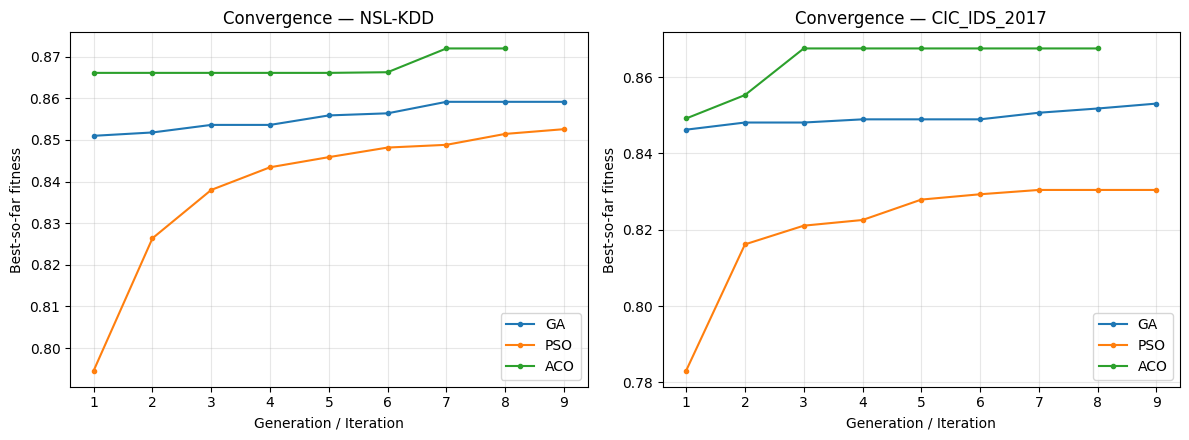

In [63]:
# ============================================================
# FIGURE 1: CONVERGENCE CURVES (best-so-far fitness per generation/iteration)
# ============================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(DATASETS), figsize=(6 * len(DATASETS), 4.5), squeeze=False)
axes = axes[0]

for ax, ds_name in zip(axes, DATASETS.keys()):
    for algo_name in ALGOS.keys():
        history = convergence_log[(ds_name, algo_name)]
        ax.plot(range(1, len(history) + 1), history, marker="o", markersize=3, label=algo_name)
    ax.set_title(f"Convergence — {ds_name}")
    ax.set_xlabel("Generation / Iteration")
    ax.set_ylabel("Best-so-far fitness")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
conv_path = os.path.join(RESULTS_DIR, "convergence_curves.png")
plt.savefig(conv_path, dpi=150)
print("Saved:", conv_path)
plt.show()


Saved: results/algorithm_comparison.png


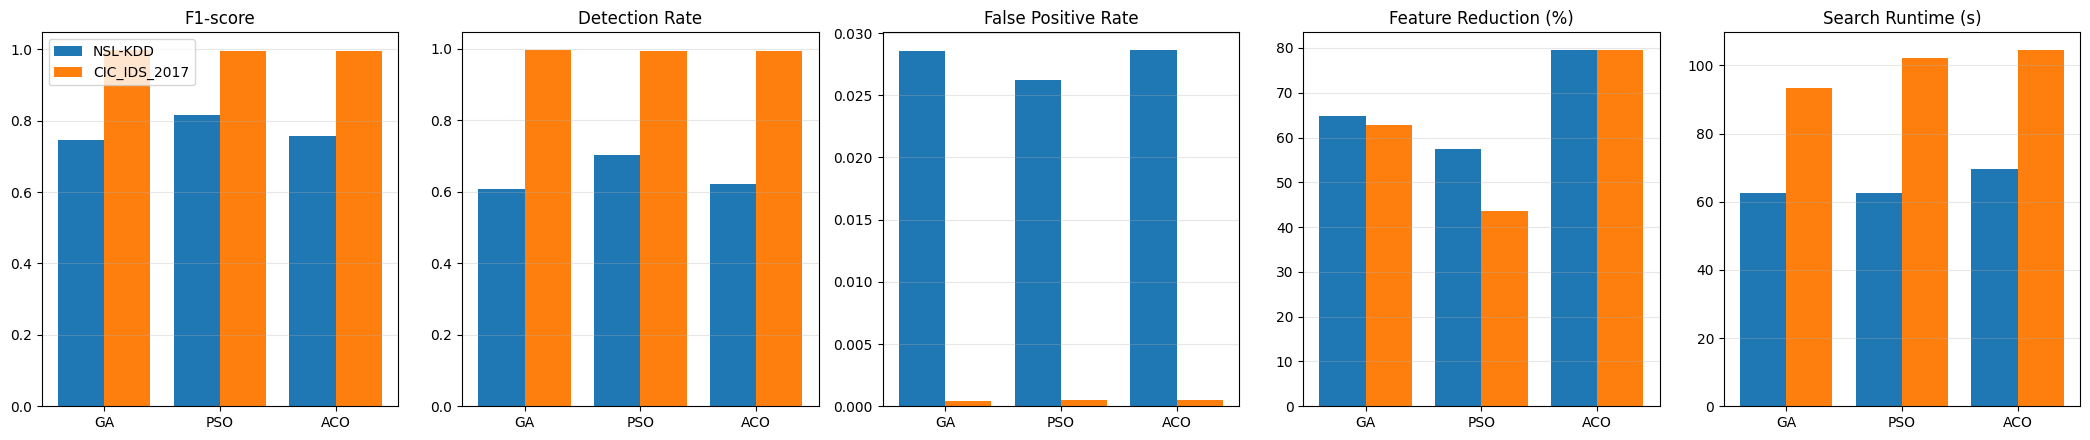

In [64]:
# ============================================================
# FIGURE 2: CROSS-ALGORITHM COMPARISON (grouped bar charts)
# ============================================================
metrics_to_plot = ["f1", "recall_DR", "fpr", "feature_reduction_pct", "runtime_sec"]
metric_labels = {
    "f1": "F1-score", "recall_DR": "Detection Rate", "fpr": "False Positive Rate",
    "feature_reduction_pct": "Feature Reduction (%)", "runtime_sec": "Search Runtime (s)"
}

fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(4.2 * len(metrics_to_plot), 4.5))

ds_list = list(DATASETS.keys())
algo_list = list(ALGOS.keys())
bar_width = 0.8 / len(ds_list)

for ax, metric in zip(axes, metrics_to_plot):
    for d_idx, ds_name in enumerate(ds_list):
        vals = [results_df[(results_df.dataset == ds_name) & (results_df.algorithm == a)][metric].values[0]
                for a in algo_list]
        x = np.arange(len(algo_list)) + d_idx * bar_width
        ax.bar(x, vals, width=bar_width, label=ds_name)
    ax.set_xticks(np.arange(len(algo_list)) + bar_width * (len(ds_list) - 1) / 2)
    ax.set_xticklabels(algo_list)
    ax.set_title(metric_labels[metric])
    ax.grid(alpha=0.3, axis="y")

axes[0].legend()
plt.tight_layout()
cmp_path = os.path.join(RESULTS_DIR, "algorithm_comparison.png")
plt.savefig(cmp_path, dpi=150)
print("Saved:", cmp_path)
plt.show()


## (Optional, slow) Statistical validation — Section IV-F
`N_STAT_RUNS` independent repetitions per algorithm/dataset, compared with
Wilcoxon rank-sum (pairwise) and Friedman (all three) tests on F1-score.
Only run this once the main-results cell above works — it multiplies the
runtime by roughly `N_STAT_RUNS`.

In [65]:
# ============================================================
# STATISTICAL VALIDATION (OPTIONAL — SLOW)
# ============================================================
stat_records = []

for ds_name, (X_train, X_test, y_train, y_test, feat_names) in DATASETS.items():
    for algo_name, algo_fn in ALGOS.items():
        for run in range(N_STAT_RUNS):
            seed = 100 + run
            fitness_fn, n_features = make_fitness_fn(X_train, y_train, random_state=seed)
            mask, _, _ = algo_fn(fitness_fn, n_features, random_state=seed)
            metrics = evaluate_subset(mask, X_train, y_train, X_test, y_test, random_state=seed)
            stat_records.append(dict(dataset=ds_name, algorithm=algo_name, run=run, f1=metrics["f1"]))
        print(f"  done: {ds_name} / {algo_name}")

stat_df = pd.DataFrame(stat_records)
stat_df.to_csv(os.path.join(RESULTS_DIR, "statistical_runs.csv"), index=False)

print("\nPairwise Wilcoxon rank-sum tests (F1 scores):")
algos = list(ALGOS.keys())
for ds_name in DATASETS:
    sub = stat_df[stat_df.dataset == ds_name]
    for i in range(len(algos)):
        for j in range(i + 1, len(algos)):
            a, b = algos[i], algos[j]
            fa = sub[sub.algorithm == a].sort_values("run")["f1"].values
            fb = sub[sub.algorithm == b].sort_values("run")["f1"].values
            try:
                stat, p = wilcoxon(fa, fb)
                print(f"  [{ds_name}] {a} vs {b}: stat={stat:.3f}, p={p:.4f}")
            except ValueError as e:
                print(f"  [{ds_name}] {a} vs {b}: could not compute ({e})")

print("\nFriedman test (all 3 algorithms, per dataset):")
for ds_name in DATASETS:
    sub = stat_df[stat_df.dataset == ds_name]
    pivot = sub.pivot(index="run", columns="algorithm", values="f1")
    stat, p = friedmanchisquare(*[pivot[c].values for c in pivot.columns])
    print(f"  [{ds_name}] chi2={stat:.3f}, p={p:.4f}")


  done: NSL-KDD / GA
  done: NSL-KDD / PSO
  done: NSL-KDD / ACO
  done: CIC_IDS_2017 / GA
  done: CIC_IDS_2017 / PSO
  done: CIC_IDS_2017 / ACO

Pairwise Wilcoxon rank-sum tests (F1 scores):
  [NSL-KDD] GA vs PSO: stat=5.000, p=0.6250
  [NSL-KDD] GA vs ACO: stat=6.000, p=0.8125
  [NSL-KDD] PSO vs ACO: stat=1.000, p=0.1250
  [CIC_IDS_2017] GA vs PSO: stat=4.000, p=0.4375
  [CIC_IDS_2017] GA vs ACO: stat=6.000, p=0.8125
  [CIC_IDS_2017] PSO vs ACO: stat=5.000, p=0.6250

Friedman test (all 3 algorithms, per dataset):
  [NSL-KDD] chi2=2.800, p=0.2466
  [CIC_IDS_2017] chi2=1.200, p=0.5488


**Cell 1 — Baseline RF (all features, no selection):**

In [66]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np, time

trained_models = {}   # (dataset, algorithm) -> (clf, y_pred, y_test)
baseline_results = []

for ds_name, (X_train, X_test, y_train, y_test, feat_names) in DATASETS.items():
    n_features = X_train.shape[1]
    full_mask = np.ones(n_features, dtype=bool)

    t0 = time.time()
    clf = RandomForestClassifier(n_estimators=RF_TREES_FINAL, n_jobs=-1, random_state=42)
    clf.fit(X_train[:, full_mask], y_train)
    y_pred = clf.predict(X_test[:, full_mask])
    elapsed = time.time() - t0

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    metrics = dict(
        dataset=ds_name, algorithm="Baseline_RF_AllFeatures",
        accuracy=accuracy_score(y_test, y_pred),
        precision=precision_score(y_test, y_pred, zero_division=0),
        recall_DR=recall_score(y_test, y_pred, zero_division=0),
        f1=f1_score(y_test, y_pred, zero_division=0),
        fpr=fp / (fp + tn) if (fp + tn) > 0 else 0.0,
        n_selected=n_features, n_total=n_features, feature_reduction_pct=0.0,
        runtime_sec=round(elapsed, 2)
    )
    baseline_results.append(metrics)
    trained_models[(ds_name, "Baseline_RF_AllFeatures")] = (clf, y_pred, y_test)
    print(f"  {ds_name} baseline: Acc={metrics['accuracy']:.4f}  F1={metrics['f1']:.4f}  "
          f"DR={metrics['recall_DR']:.4f}  FPR={metrics['fpr']:.4f}  time={elapsed:.1f}s")

baseline_df = pd.DataFrame(baseline_results)
baseline_df

  NSL-KDD baseline: Acc=0.7649  F1=0.7464  DR=0.6078  FPR=0.0274  time=36.8s
  CIC_IDS_2017 baseline: Acc=0.9981  F1=0.9952  DR=0.9927  FPR=0.0006  time=45.3s


,dataset,algorithm,accuracy,precision,recall_DR,f1,fpr,n_selected,n_total,feature_reduction_pct,runtime_sec
0,NSL-KDD,Baseline_RF_AllFeatures,0.764949,0.967022,0.607808,0.746447,0.027392,122,122,0.0,36.83
1,CIC_IDS_2017,Baseline_RF_AllFeatures,0.998100,0.997619,0.992724,0.995166,0.000581,78,78,0.0,45.35


**Rebuild GA/PSO/ACO models from your already-selected features **

In [67]:
for (ds_name, algo_name), feat_list in selected_features_log.items():
    X_train, X_test, y_train, y_test, feat_names = DATASETS[ds_name]
    mask = np.array([f in feat_list for f in feat_names])

    clf = RandomForestClassifier(n_estimators=RF_TREES_FINAL, n_jobs=-1, random_state=42)
    clf.fit(X_train[:, mask], y_train)
    y_pred = clf.predict(X_test[:, mask])
    trained_models[(ds_name, algo_name)] = (clf, y_pred, y_test)

print("Rebuilt models for:", list(trained_models.keys()))

Rebuilt models for: [('NSL-KDD', 'Baseline_RF_AllFeatures'), ('CIC_IDS_2017', 'Baseline_RF_AllFeatures'), ('NSL-KDD', 'GA'), ('NSL-KDD', 'PSO'), ('NSL-KDD', 'ACO'), ('CIC_IDS_2017', 'GA'), ('CIC_IDS_2017', 'PSO'), ('CIC_IDS_2017', 'ACO')]


**Cell 3 — Combine + save + the two summary tables**

In [68]:
from IPython.display import display

combined_df = pd.concat([baseline_df, results_df], ignore_index=True)
results_path = os.path.join(RESULTS_DIR, "main_results_with_baseline.csv")
combined_df.to_csv(results_path, index=False)
print("Saved:", results_path)

print("\n=== Feature reduction summary ===")
for ds_name in DATASETS:
    sub = (combined_df[combined_df.dataset == ds_name]
           [["algorithm", "n_total", "n_selected", "feature_reduction_pct"]]
           .rename(columns={"n_total": "Original", "n_selected": "Selected",
                             "feature_reduction_pct": "Reduction (%)"})
           .sort_values("algorithm").reset_index(drop=True))
    print(f"--- {ds_name} ---")
    display(sub)

print("\n=== Runtime / accuracy / F1 summary ===")
summary_perf = (combined_df[["dataset", "algorithm", "accuracy", "f1", "recall_DR", "fpr",
                              "runtime_sec", "n_selected", "n_total"]]
                 .sort_values(["dataset", "algorithm"]).reset_index(drop=True))
display(summary_perf)

Saved: results/main_results_with_baseline.csv

=== Feature reduction summary ===
--- NSL-KDD ---


,algorithm,Original,Selected,Reduction (%)
0,ACO,122,25,79.508197
1,Baseline_RF_AllFeatures,122,122,0.000000
2,GA,122,43,64.754098
3,PSO,122,52,57.377049


--- CIC_IDS_2017 ---


,algorithm,Original,Selected,Reduction (%)
0,ACO,78,16,79.487179
1,Baseline_RF_AllFeatures,78,78,0.000000
2,GA,78,29,62.820513
3,PSO,78,44,43.589744



=== Runtime / accuracy / F1 summary ===


,dataset,algorithm,accuracy,f1,recall_DR,fpr,runtime_sec,n_selected,n_total
0,CIC_IDS_2017,ACO,0.998533,0.996272,0.994755,0.000540,104.47,16,78
1,CIC_IDS_2017,Baseline_RF_AllFeatures,0.998100,0.995166,0.992724,0.000581,45.35,78,78
2,CIC_IDS_2017,GA,0.998967,0.997375,0.996447,0.000415,93.24,29,78
3,CIC_IDS_2017,PSO,0.998167,0.995335,0.992893,0.000540,102.15,44,78
4,NSL-KDD,ACO,0.772711,0.757133,0.622380,0.028627,69.63,25,122
5,NSL-KDD,Baseline_RF_AllFeatures,0.764949,0.746447,0.607808,0.027392,36.83,122,122
6,NSL-KDD,GA,0.764416,0.745995,0.607730,0.028524,62.42,43,122
7,NSL-KDD,PSO,0.819375,0.815780,0.702564,0.026259,62.47,52,122


**Cell 4 — Confusion matrix heatmaps**

Saved: results/confusion_matrices.png


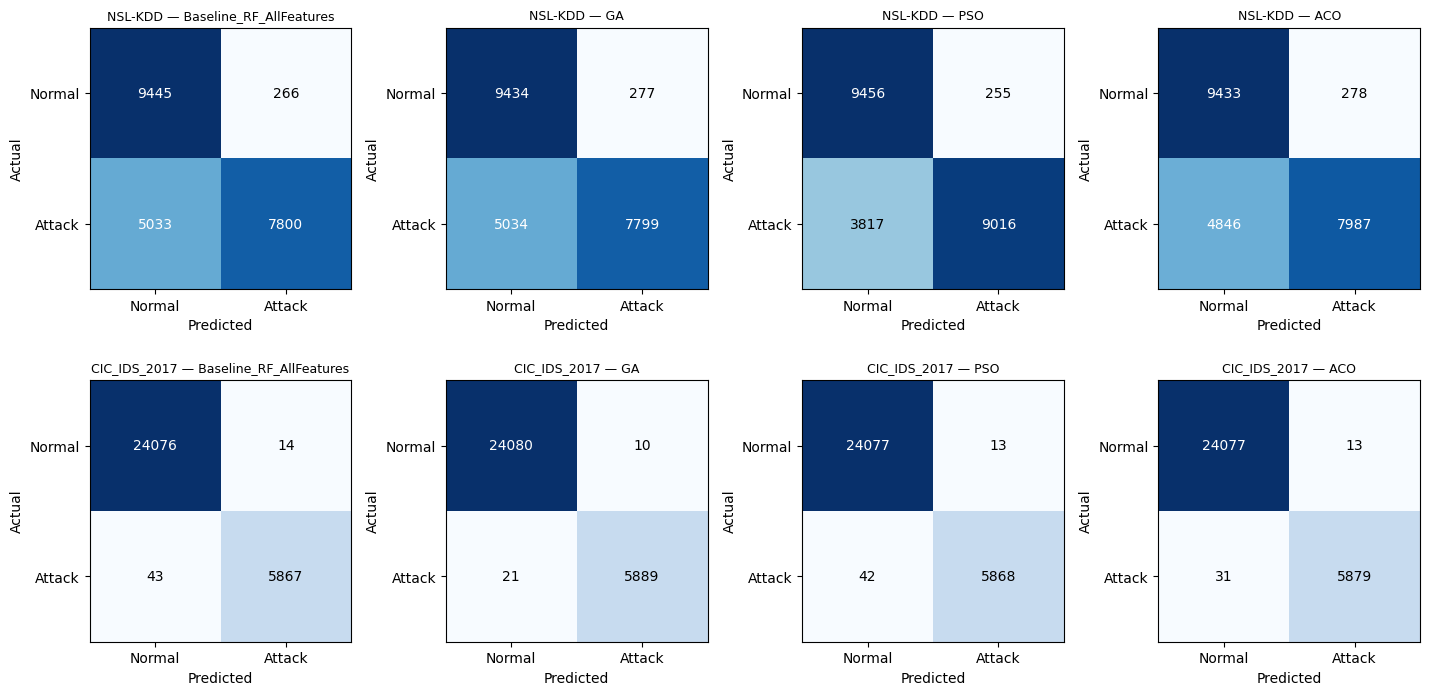

In [69]:
import matplotlib.pyplot as plt

plot_order = ["Baseline_RF_AllFeatures", "GA", "PSO", "ACO"]
labels = ["Normal", "Attack"]

fig, axes = plt.subplots(len(DATASETS), len(plot_order),
                          figsize=(3.6 * len(plot_order), 3.6 * len(DATASETS)))
if len(DATASETS) == 1:
    axes = axes[np.newaxis, :]

for row, ds_name in enumerate(DATASETS.keys()):
    for col, algo_name in enumerate(plot_order):
        ax = axes[row, col]
        clf, y_pred, y_test_local = trained_models[(ds_name, algo_name)]
        cm = confusion_matrix(y_test_local, y_pred)
        ax.imshow(cm, cmap="Blues")
        for i in range(cm.shape[0]):
            for j in range(cm.shape[1]):
                ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(labels)
        ax.set_yticks([0, 1]); ax.set_yticklabels(labels)
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
        ax.set_title(f"{ds_name} — {algo_name}", fontsize=9)

plt.tight_layout()
cm_path = os.path.join(RESULTS_DIR, "confusion_matrices.png")
plt.savefig(cm_path, dpi=150)
print("Saved:", cm_path)
plt.show()

**Cell 5 — Optional: save the trained models:**

In [71]:
import joblib

SAVE_MODELS = False   # flip to True if you want to keep these classifiers

if SAVE_MODELS:
    models_dir = os.path.join(RESULTS_DIR, "models")
    os.makedirs(models_dir, exist_ok=True)
    for (ds_name, algo_name), (clf, y_pred, y_test_local) in trained_models.items():
        fname = os.path.join(models_dir, f"{ds_name}_{algo_name}_rf.joblib")
        joblib.dump(clf, fname)
        print("Saved:", fname)